In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold

import torch
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader

# ~30s or less

# Loading in the data

In [ ]:
ROOT = Path(".")
IMG_DIR = ROOT / "Image"

FOLDERS = ["Normal", "Stage 1 ROP", "Stage 2 ROP", "Stage 3 ROP", "Stage 4 ROP", "Stage 5 ROP"]

# one row per image file, stacked across class folders
files = pd.concat(
    [pd.DataFrame({"image": [p.name for p in sorted((IMG_DIR / f).iterdir())
                             if p.suffix.lower() in {".jpg", ".jpeg"}],
                   "label": f})
     for f in FOLDERS],
    ignore_index=True,
)
files["path"] = [str(IMG_DIR / lab / name) for lab, name in zip(files["label"], files["image"])]

# attach patient metadata by filename
info = pd.read_excel(ROOT / "img_info.xlsx")
imgs = files.merge(info, on="image", how="left", validate="one_to_one").rename(columns={"image": "file"})
assert imgs["patient_id"].notna().all(), "some images are missing from img_info.xlsx"

SEVERITY = {"Stage 1 ROP": "Mild ROP", "Stage 2 ROP": "Mild ROP", "Stage 3 ROP": "Moderate ROP",
            "Stage 4 ROP": "Severe ROP", "Stage 5 ROP": "Severe ROP"}
imgs["severity"] = imgs["label"].map(SEVERITY)           
imgs["ROP"] = (imgs["label"] != "Normal").astype(int)    

print("imgs:", imgs.shape[0])
print("features:", imgs.columns)

# ~3s or less

imgs: 1527
features: Index(['file', 'label', 'path', 'patient_id', 'gender', 'gestational_age',
       'birth_weight', 'plurality', 'delivery_mode', 'categories', 'severity',
       'ROP'],
      dtype='str')


# Loading in the images

In [ ]:
# Image dimensions when loaded in
size = 512

def load(p, size):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize(size))

# Opening the jpeg images as numpy arrays with the standardized size
imgs["image"] = imgs["path"].apply(lambda p: load(p, (size,size)))   

# Better to seperate the memory heavy image data from the rest of the data
X_all = np.stack(imgs["image"].values)
imgs = imgs.drop(columns="image")

# ~1m 13s or less

# 5-fold cross-validation

In [ ]:
# Similar to the regular KFold() function but able to handle stratification
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# Initilizing as -1 makes overlooking skipped rows harder to overlook
imgs["fold"] = -1
# y = label to stratify on, every group stays in the same fold (so patients stay in the same fold)
for k, (train_idx, val_idx) in enumerate(sgkf.split(X=imgs, y=imgs["label"], groups=imgs["patient_id"])):
    # assigning images to a fold
    imgs.loc[val_idx, "fold"] = k

print("every image is in a fold:", (imgs["fold"] >= 0).all())
print("No patient is split between folds:", imgs.groupby("patient_id")["fold"].nunique().max() == 1)

# <1s

every image is in a fold: True
No patient is split between folds: True


# Data pre-processing and augmentation transformers

In [ ]:
# Compose() chains a list of transforms into a single callable that applies them in order
# where v2 is what is being transformed
train_tf = v2.Compose([
    v2.ToImage(),                                    # HWC uint8 array -> CHW tensor
    v2.ToDtype(torch.float32, scale=True),           # intensity normalization: [0, 255] -> [0, 1]
    v2.RandomHorizontalFlip(p=0.5),                  # random horizontal flip
    v2.RandomAffine(degrees=5, scale=(0.9, 1.1),     # rotation in [-5, 5] deg and scale in [0.9, 1.1], one resampling step
                    interpolation=v2.InterpolationMode.BILINEAR, fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0),
])

val_tf = v2.Compose([                                # validation: normalization only
    v2.ToImage(),                                    # no augmentation
    v2.ToDtype(torch.float32, scale=True),
])

# <1s

# Assigning a dataset for each task

In [ ]:
# ROP occurence task
occ_df = imgs.assign(y=imgs["ROP"])
# severity task
sev_df = imgs[imgs["severity"].notna()].assign(
    # encoding
    y=lambda d: d["severity"].map({"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}))

print("-------[Occurence Task]-------")
print("occurence task unique patients:", occ_df["patient_id"].unique().shape[0])
print("occurence task images:", occ_df.shape[0])
print("num classes:", occ_df["ROP"].unique().shape[0])
print(pd.crosstab(imgs["ROP"], imgs["fold"]))
print("\n")
print("-------[Severity Task]-------")
print("severity task unique patients:", sev_df["patient_id"].unique().shape[0])
print("severity task images:", sev_df.shape[0])
print("num classes:", sev_df["severity"].unique().shape[0])
print(pd.crosstab(imgs["severity"], imgs["fold"]))

# <1s

-------[Occurence Task]-------
occurence task unique patients: 916
occurence task images: 1527
num classes: 2
fold    0    1    2    3    4
ROP                          
0     124  125  124  125  125
1     182  181  181  180  180


-------[Severity Task]-------
severity task unique patients: 550
severity task images: 904
num classes: 3
fold            0    1    2    3    4
severity                             
Mild ROP      116  114  115  114  115
Moderate ROP   48   49   48   48   48
Severe ROP     18   18   18   18   17


# Image Loader

In [ ]:
class ROPDataset(Dataset):
    """Hands the DataLoader one (image, label) pair at a time, applying the transform on the fly."""

    def __init__(self, X, idx, y, tf):
        # X   : the full image array (1527, 512, 512, 3), uint8. Stored by reference, not copied.
        # idx : row numbers in X that belong to this dataset (e.g. this fold's training rows)
        # y   : labels for those same rows, in the same order as idx
        # tf  : transform pipeline (train_tf or val_tf)
        # np.asarray turns the pandas Index / Series into plain numpy arrays
        self.X, self.idx, self.y, self.tf = X, np.asarray(idx), np.asarray(y), tf

    def __len__(self):
        # the DataLoader calls this to know how many samples there are (which sets batches per epoch)
        return len(self.idx)

    def __getitem__(self, i):
        # i is a position within this dataset (0 .. len-1), not a row number in X.
        # self.idx[i] translates it to the row in X, and self.X[...] is one (512, 512, 3) uint8 image.
        # self.tf(...) returns a float tensor (3, 512, 512). The random steps in train_tf are
        # re-drawn on every call, so the same image looks different each epoch (X itself isn't modified).
        # int(self.y[i]) is a plain Python int label; the DataLoader stacks these into a tensor.
        return self.tf(self.X[self.idx[i]]), int(self.y[i])


def make_loaders(df, k, bs=16):
    # df: occ_df or sev_df (needs "fold" and "y" columns). k: the fold held out for validation.
    tr, va = df[df["fold"] != k], df[df["fold"] == k]    # four folds to train on, one to validate on

    # tr.index holds the original row numbers in imgs / X_all (they survive the filtering),
    # and tr["y"] holds their labels in the same order
    train_dl = DataLoader(ROPDataset(X_all, tr.index, tr["y"], train_tf), batch_size=bs, shuffle=True)  # new order each epoch
    val_dl   = DataLoader(ROPDataset(X_all, va.index, va["y"], val_tf),   batch_size=bs)               # no shuffle: order stays fixed
    # DataLoader() provides effecient data handling during training and evaluation
    return train_dl, val_dl

# <1s

# Testing augmentation

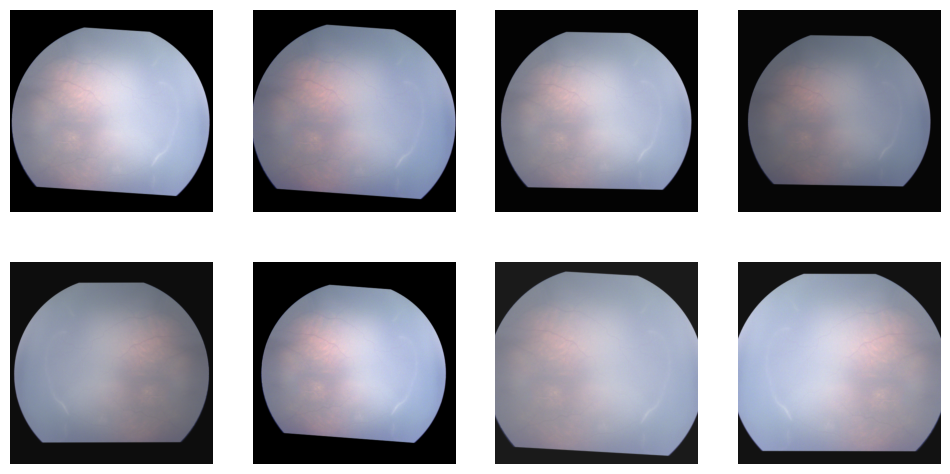

In [ ]:
# X_all is all the images only
img = X_all[sev_df.index[0]] # gets an index for the image data
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
# Do 8 times for the same image
for ax in axes.flat:
    ax.imshow(train_tf(img).permute(1, 2, 0).clamp(0, 1).numpy())
    # train_tf applies the transforms to a given image (roation, color jitter, etc)
    # permute() changes the tensors shape from (channels, height, width) to (hight, width, channels)
    # clamp(0,1) ensures the pixels are within a valid range for images
    # numpy() converts the tensor to a numpy array
    ax.axis("off")

# <1s